<center><h1>Muhammad Abdullah </h1>
<h3>F22607010</h3></center>

<h3>Task 1: Load and Preprocess the MNIST Dataset</h3>


In [2]:
import numpy as np
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalizing the data (to values between 0 and 1)
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# Flatteniing the images to 1D vectors (28x28 -> 784)
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# One-hot encoding the images label
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)


<h3>Task 2: Build the Model</h3>

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

#bulding the squential Model 

def build_model():
    model = Sequential([
        Dense(128, activation='relu', input_shape=(784,)),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])
    return model


<h3>Task 3: Train the Model with Different Gradient Descent and Learning Rate Strategies</h3>

<h4>SGD with Fixed Learning Rate (Batch Size 1)</h4>

In [28]:
from tensorflow.keras.optimizers import SGD
import time

model = build_model()
optimizer = SGD(learning_rate=0.01)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_sgd_fixed = model.fit(x_train, y_train, batch_size=1, epochs=5, validation_data=(x_test, y_test))
training_time_sgd_fixed =  (time.time() - start_time)
print("Training Time: %s seconds" % training_time_sgd_fixed)


Epoch 1/5
60000/60000 [==============================] - 136s 2ms/step - loss: 0.2256 - accuracy: 0.9301 - val_loss: 0.1256 - val_accuracy: 0.9613
Epoch 2/5
60000/60000 [==============================] - 155s 3ms/step - loss: 0.1074 - accuracy: 0.9669 - val_loss: 0.1187 - val_accuracy: 0.9626
Epoch 3/5
60000/60000 [==============================] - 148s 2ms/step - loss: 0.0801 - accuracy: 0.9751 - val_loss: 0.0973 - val_accuracy: 0.9696
Epoch 4/5
60000/60000 [==============================] - 117s 2ms/step - loss: 0.0625 - accuracy: 0.9806 - val_loss: 0.0946 - val_accuracy: 0.9721
Epoch 5/5
60000/60000 [==============================] - 114s 2ms/step - loss: 0.0523 - accuracy: 0.9831 - val_loss: 0.1083 - val_accuracy: 0.9693
Training Time: 671.214136838913 seconds


<h4>Full Batch Gradient Descent with Fixed Learning Rate (Batch Size = Total Data Size)</h4>

In [31]:
model = build_model()
optimizer = SGD(learning_rate=0.01)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_full_batch = model.fit(x_train, y_train, batch_size=x_train.shape[0], epochs=5, validation_data=(x_test, y_test))
training_time_full_batch = (time.time() - start_time)
print(f"Training Time: {training_time_full_batch} seconds")

Epoch 1/5
1/1 [==============================] - 4s 4s/step - loss: 2.3223 - accuracy: 0.1241 - val_loss: 2.3174 - val_accuracy: 0.1233
Epoch 2/5
1/1 [==============================] - 0s 415ms/step - loss: 2.3171 - accuracy: 0.1266 - val_loss: 2.3121 - val_accuracy: 0.1260
Epoch 3/5
1/1 [==============================] - 0s 400ms/step - loss: 2.3120 - accuracy: 0.1294 - val_loss: 2.3070 - val_accuracy: 0.1293
Epoch 4/5
1/1 [==============================] - 0s 384ms/step - loss: 2.3070 - accuracy: 0.1317 - val_loss: 2.3019 - val_accuracy: 0.1319
Epoch 5/5
1/1 [==============================] - 0s 333ms/step - loss: 2.3021 - accuracy: 0.1343 - val_loss: 2.2969 - val_accuracy: 0.1353
Training Time: 5.77057671546936 seconds


<h4>Mini-Batch Gradient Descent with Batch Sizes 32 and 1000</h4>

In [27]:
#with Batch size 32
model = build_model()
optimizer = SGD(learning_rate=0.01)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_mini_32 = model.fit(x_train, y_train, batch_size=32, epochs=5, validation_data=(x_test, y_test))
training_time_mini_32 =  (time.time() - start_time)
print("Training Time: %s seconds" % training_time_mini_32 )

#with Batch size 1000
model = build_model()
optimizer = SGD(learning_rate=0.01)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_mini_1000 = model.fit(x_train, y_train, batch_size=1000, epochs=5, validation_data=(x_test, y_test))
training_time_mini_1000 = (time.time() - start_time)
print("Training Time: %s seconds" % training_time_mini_1000)

Epoch 1/5
1875/1875 [==============================] - 7s 3ms/step - loss: 0.6176 - accuracy: 0.8371 - val_loss: 0.3118 - val_accuracy: 0.9144
Epoch 2/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.2871 - accuracy: 0.9192 - val_loss: 0.2443 - val_accuracy: 0.9313
Epoch 3/5
1875/1875 [==============================] - 5s 3ms/step - loss: 0.2352 - accuracy: 0.9327 - val_loss: 0.2154 - val_accuracy: 0.9372
Epoch 4/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.2023 - accuracy: 0.9420 - val_loss: 0.1881 - val_accuracy: 0.9445
Epoch 5/5
1875/1875 [==============================] - 7s 4ms/step - loss: 0.1782 - accuracy: 0.9495 - val_loss: 0.1688 - val_accuracy: 0.9520
Training Time: 30.732492685317993 seconds
Epoch 1/5
60/60 [==============================] - 1s 15ms/step - loss: 2.1427 - accuracy: 0.2319 - val_loss: 1.9734 - val_accuracy: 0.4124
Epoch 2/5
60/60 [==============================] - 1s 10ms/step - loss: 1.8169 - accuracy: 0.5557 - val

<h4>Mini-Batch Gradient Descent with Adaptive Global Learning Rate</h4>

In [26]:
from tensorflow.keras.optimizers.schedules import ExponentialDecay

learning_rate_schedule = ExponentialDecay(initial_learning_rate=0.01, decay_steps=10000, decay_rate=0.96)
optimizer = SGD(learning_rate=learning_rate_schedule)

model = build_model()
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_adaptive_lr = model.fit(x_train, y_train, batch_size=32, epochs=5, validation_data=(x_test, y_test))
training_time_adaptive_lr = (time.time() - start_time)

print(f"Training Time: {training_time_adaptive_lr} seconds")


Epoch 1/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.6407 - accuracy: 0.8306 - val_loss: 0.3147 - val_accuracy: 0.9097
Epoch 2/5
1875/1875 [==============================] - 7s 4ms/step - loss: 0.2881 - accuracy: 0.9179 - val_loss: 0.2475 - val_accuracy: 0.9281
Epoch 3/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.2327 - accuracy: 0.9338 - val_loss: 0.2085 - val_accuracy: 0.9408
Epoch 4/5
1875/1875 [==============================] - 5s 3ms/step - loss: 0.1977 - accuracy: 0.9435 - val_loss: 0.1831 - val_accuracy: 0.9458
Epoch 5/5
1875/1875 [==============================] - 5s 3ms/step - loss: 0.1730 - accuracy: 0.9504 - val_loss: 0.1663 - val_accuracy: 0.9519
Training Time: 29.98255181312561 seconds


<h4>Mini-Batch Gradient Descent with Adagrad Optimizer</h4>

In [25]:
from tensorflow.keras.optimizers import Adagrad

model = build_model()
optimizer = Adagrad()
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_adagrad = model.fit(x_train, y_train, batch_size=32, epochs=5, validation_data=(x_test, y_test))
training_time_adagrad = (time.time() - start_time)
print("Training Time: %s seconds" % training_time_adagrad)


Epoch 1/5
1875/1875 [==============================] - 7s 3ms/step - loss: 1.3524 - accuracy: 0.6661 - val_loss: 0.7189 - val_accuracy: 0.8444
Epoch 2/5
1875/1875 [==============================] - 7s 4ms/step - loss: 0.6026 - accuracy: 0.8565 - val_loss: 0.4842 - val_accuracy: 0.8810
Epoch 3/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.4656 - accuracy: 0.8799 - val_loss: 0.4068 - val_accuracy: 0.8973
Epoch 4/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.4078 - accuracy: 0.8914 - val_loss: 0.3674 - val_accuracy: 0.9025
Epoch 5/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.3744 - accuracy: 0.8983 - val_loss: 0.3424 - val_accuracy: 0.9091
Training Time: 31.26030683517456 seconds


<h3>Task 4: Mini-Batch Gradient Descent with Momentum and Nesterov Momentum</h3>
Momentum

In [23]:
optimizer = SGD(learning_rate=0.01, momentum=0.9)

model = build_model()
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_momentum = model.fit(x_train, y_train, batch_size=32, epochs=5, validation_data=(x_test, y_test))
training_time_momentum = (time.time() - start_time)
print("Training Time: %s seconds" % training_time_momentum)



Epoch 1/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.2839 - accuracy: 0.9158 - val_loss: 0.1418 - val_accuracy: 0.9570
Epoch 2/5
1875/1875 [==============================] - 5s 3ms/step - loss: 0.1194 - accuracy: 0.9641 - val_loss: 0.1004 - val_accuracy: 0.9698
Epoch 3/5
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0838 - accuracy: 0.9740 - val_loss: 0.0939 - val_accuracy: 0.9705
Epoch 4/5
1875/1875 [==============================] - 5s 3ms/step - loss: 0.0646 - accuracy: 0.9804 - val_loss: 0.0817 - val_accuracy: 0.9733
Epoch 5/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0523 - accuracy: 0.9831 - val_loss: 0.0797 - val_accuracy: 0.9754
Training Time: 26.10271453857422 seconds


Nesterov Momentum

In [24]:
optimizer = SGD(learning_rate=0.01, momentum=0.9, nesterov=True)

model = build_model()
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

start_time = time.time()
history_nesterov = model.fit(x_train, y_train, batch_size=32, epochs=5, validation_data=(x_test, y_test))
training_time_nesterov = (time.time() - start_time)
print("Training Time: %s seconds" % training_time_nesterov)


Epoch 1/5
1875/1875 [==============================] - 8s 4ms/step - loss: 0.2844 - accuracy: 0.9163 - val_loss: 0.1327 - val_accuracy: 0.9609
Epoch 2/5
1875/1875 [==============================] - 11s 6ms/step - loss: 0.1170 - accuracy: 0.9643 - val_loss: 0.1057 - val_accuracy: 0.9679
Epoch 3/5
1875/1875 [==============================] - 9s 5ms/step - loss: 0.0834 - accuracy: 0.9749 - val_loss: 0.1021 - val_accuracy: 0.9687
Epoch 4/5
1875/1875 [==============================] - 7s 4ms/step - loss: 0.0645 - accuracy: 0.9798 - val_loss: 0.0786 - val_accuracy: 0.9759
Epoch 5/5
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0501 - accuracy: 0.9845 - val_loss: 0.0881 - val_accuracy: 0.9717
Training Time: 41.22076487541199 seconds


<h3>Task 5: Plotting Results</h3>

In [29]:
import matplotlib.pyplot as plt

# Plot function
def plot_results(history, title):
    plt.plot(history.history['accuracy'], label='train accuracy')
    plt.plot(history.history['val_accuracy'], label='val accuracy')
    plt.plot(history.history['loss'], label='train loss')
    plt.plot(history.history['val_loss'], label='val loss')
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy / Loss')
    plt.legend()
    plt.show()

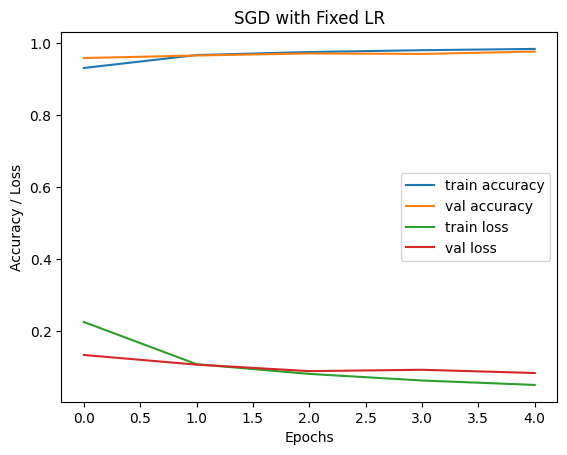

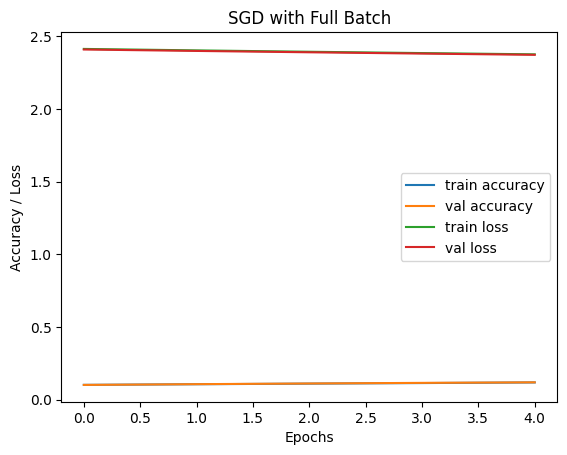

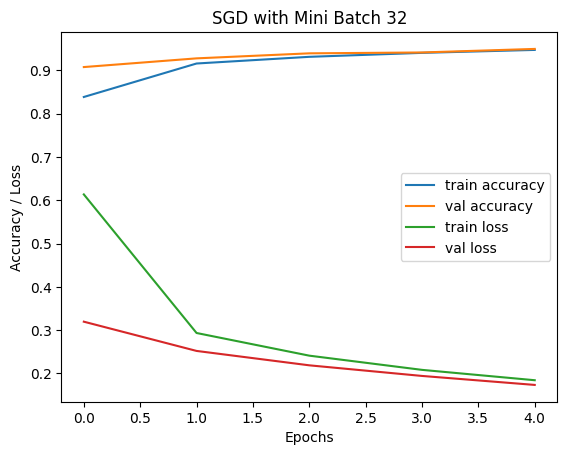

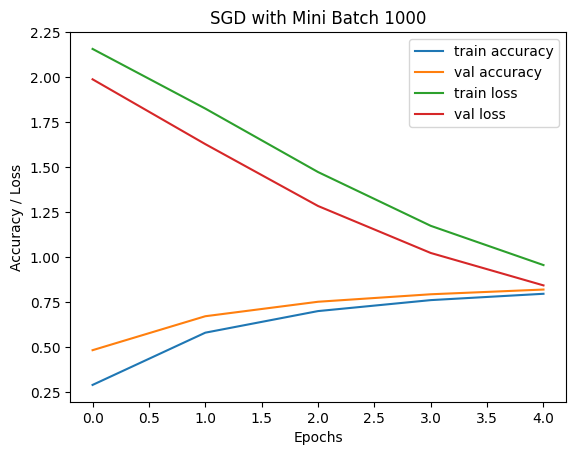

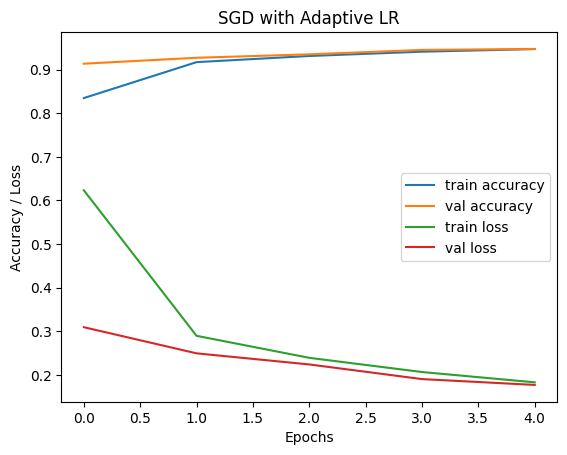

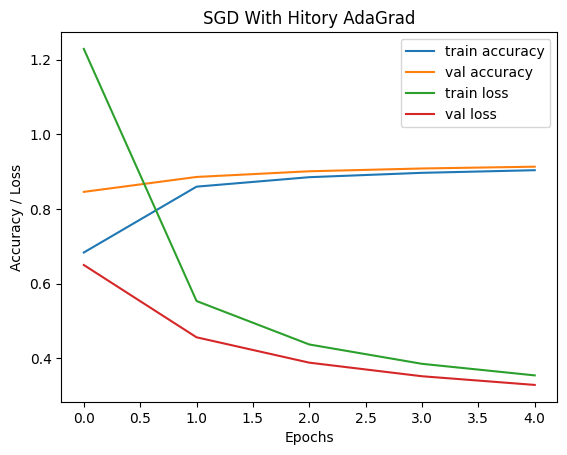

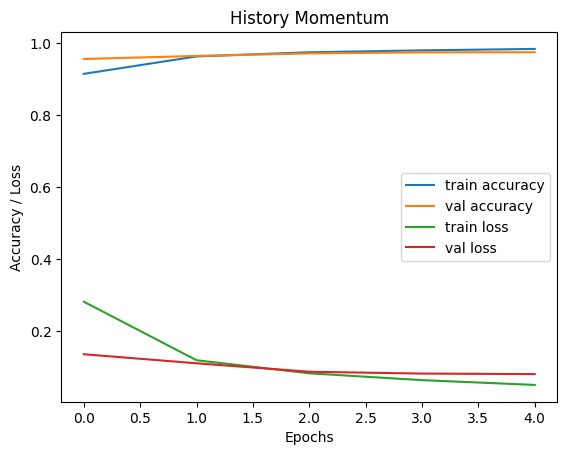

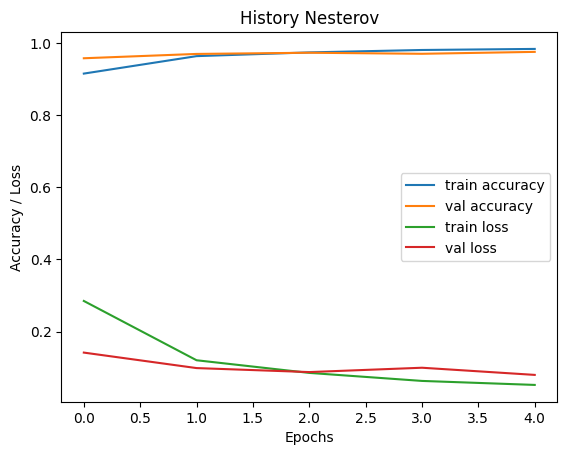

In [13]:

plot_results(history_sgd_fixed, "SGD with Fixed LR")
plot_results(history_full_batch, "SGD with Full Batch")
plot_results(history_mini_32, "SGD with Mini Batch 32")
plot_results(history_mini_1000, "SGD with Mini Batch 1000")
plot_results(history_adaptive_lr, "SGD with Adaptive LR")
plot_results(history_adagrad, "SGD With Hitory AdaGrad")
plot_results(history_momentum, "History Momentum")
plot_results(history_nesterov , "History Nesterov")


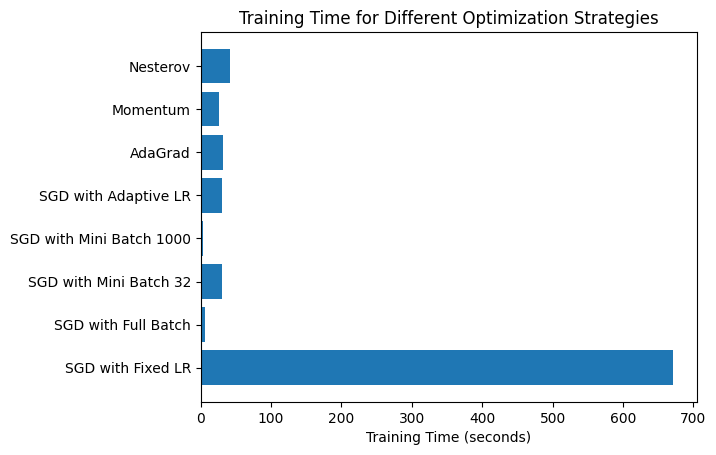

In [32]:
# Training times (seconds) for each strategy
training_times = [
    training_time_sgd_fixed,    
    training_time_full_batch,   
    training_time_mini_32,      
    training_time_mini_1000, 
    training_time_adaptive_lr,
    training_time_adagrad,    
    training_time_momentum,   
    training_time_nesterov
]

strategies = [
    "SGD with Fixed LR",
    "SGD with Full Batch",
    "SGD with Mini Batch 32",
    "SGD with Mini Batch 1000",
    "SGD with Adaptive LR",
    "AdaGrad",
    "Momentum",
    "Nesterov"
]


plt.barh(strategies, training_times)
plt.xlabel('Training Time (seconds)')
plt.title('Training Time for Different Optimization Strategies')
plt.show()


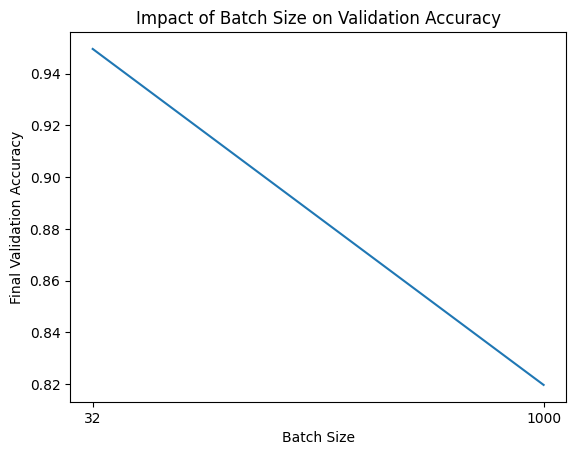

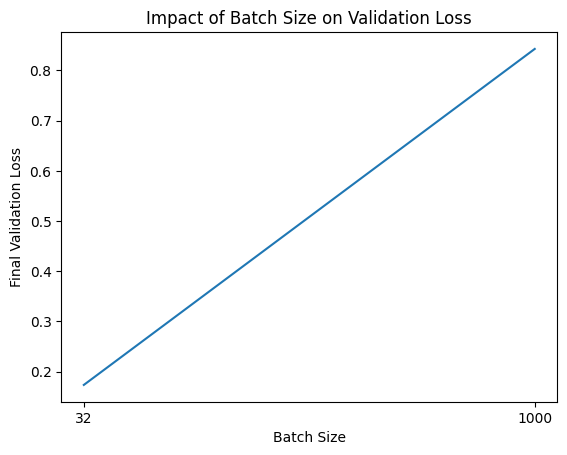

In [21]:
batch_sizes = ["32", "1000"]
mini_batch_acc = [history_mini_32.history['val_accuracy'][-1], history_mini_1000.history['val_accuracy'][-1]]
mini_batch_loss = [history_mini_32.history['val_loss'][-1], history_mini_1000.history['val_loss'][-1]]

plt.plot(batch_sizes, mini_batch_acc)
plt.xlabel('Batch Size')
plt.ylabel('Final Validation Accuracy')
plt.title('Impact of Batch Size on Validation Accuracy')
plt.show()

plt.plot(batch_sizes, mini_batch_loss)
plt.xlabel('Batch Size')
plt.ylabel('Final Validation Loss')
plt.title('Impact of Batch Size on Validation Loss')
plt.show()


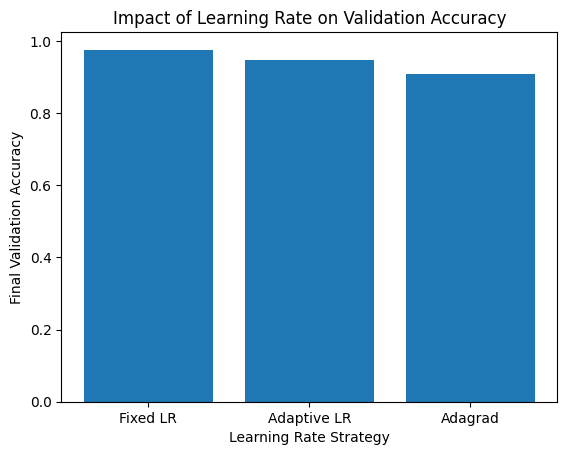

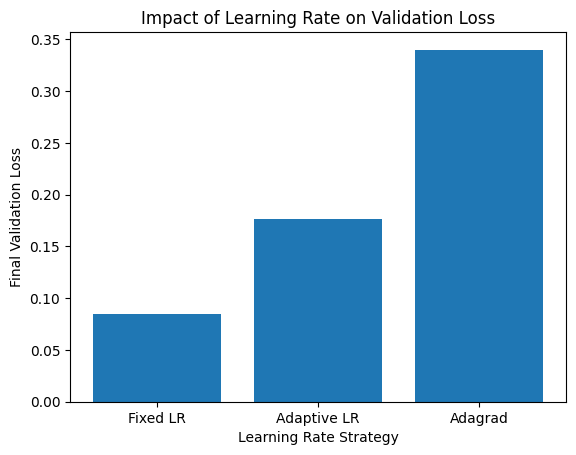

In [17]:
lr_strategies = ["Fixed LR", "Adaptive LR", "Adagrad"]
lr_acc = [history_sgd_fixed.history['val_accuracy'][-1], history_adaptive_lr.history['val_accuracy'][-1], history_adagrad.history['val_accuracy'][-1]]
lr_loss = [history_sgd_fixed.history['val_loss'][-1], history_adaptive_lr.history['val_loss'][-1], history_adagrad.history['val_loss'][-1]]

plt.bar(lr_strategies, lr_acc)
plt.xlabel('Learning Rate Strategy')
plt.ylabel('Final Validation Accuracy')
plt.title('Impact of Learning Rate on Validation Accuracy')
plt.show()

plt.bar(lr_strategies, lr_loss)
plt.xlabel('Learning Rate Strategy')
plt.ylabel('Final Validation Loss')
plt.title('Impact of Learning Rate on Validation Loss')
plt.show()


### **Resources Used**

 1. **Tensorflow Documentation** `(https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD)`
 `(https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adagrad)`
